ARTI308 - Machine Learning

# Assignment 2: Data Quality Assessment & Preprocessing

In real-world machine learning projects, data is often:
- Incomplete (missing values)
- Noisy (outliers or random errors)
- Inconsistent (wrong formats, mixed units)

Before building any machine learning model, we must clean and prepare the data properly.

![step2.png](img/step2.png)

In this lab, we will apply practical preprocessing techniques step by step.

In [1]:
# Install kagglehub if you don't have it (runs silently)
!pip install kagglehub -q

# Import Libraries
import kagglehub
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

## Task 1: Load Data & Identify Quality Issues
We will pull the "Rain in Australia" dataset directly from Kaggle. This avoids downloading a massive file locally.

In [3]:
# Download the dataset directly from Kaggle (No API key needed for public datasets)
path = kagglehub.dataset_download("jsphyg/weather-dataset-rattle-package")

# Load the CSV into pandas
df = pd.read_csv(f"{path}/weatherAUS.csv")

print(f"Massive Dataset Loaded! Shape: {df.shape}")

# Save a tiny sample locally to submit to the assignment folder
df.head(100).to_csv("Sample_Weather_Data.csv", index=False)

df.head()

100%|██████████| 3.83M/3.83M [00:01<00:00, 2.33MB/s]

Extracting files...


Massive Dataset Loaded! Shape: (145460, 23)


,Date,Location,MinTemp,MaxTemp,Rainfall,Evaporation,Sunshine,WindGustDir,WindGustSpeed,WindDir9am,WindDir3pm,WindSpeed9am,WindSpeed3pm,Humidity9am,Humidity3pm,Pressure9am,Pressure3pm,Cloud9am,Cloud3pm,Temp9am,Temp3pm,RainToday,RainTomorrow
0,2008-12-01,Albury,13.4,22.9,0.6,NaN,NaN,W,44.0,W,WNW,20.0,24.0,71.0,22.0,1007.7,1007.1,8.0,NaN,16.9,21.8,No,No
1,2008-12-02,Albury,7.4,25.1,0.0,NaN,NaN,WNW,44.0,NNW,WSW,4.0,22.0,44.0,25.0,1010.6,1007.8,NaN,NaN,17.2,24.3,No,No
2,2008-12-03,Albury,12.9,25.7,0.0,NaN,NaN,WSW,46.0,W,WSW,19.0,26.0,38.0,30.0,1007.6,1008.7,NaN,2.0,21.0,23.2,No,No
3,2008-12-04,Albury,9.2,28.0,0.0,NaN,NaN,NE,24.0,SE,E,11.0,9.0,45.0,16.0,1017.6,1012.8,NaN,NaN,18.1,26.5,No,No
4,2008-12-05,Albury,17.5,32.3,1.0,NaN,NaN,W,41.0,ENE,NW,7.0,20.0,82.0,33.0,1010.8,1006.0,7.0,8.0,17.8,29.7,No,No


## 2. Data Quality Assessment
### 2.1 Check Data Types
Data types must match the real meaning of each column.
For example:
- `Date` should be datetime
- `Revenue` should be numeric

In [4]:
# Check Data Types
print(df.dtypes)

Date                 str
Location             str
MinTemp          float64
MaxTemp          float64
Rainfall         float64
Evaporation      float64
Sunshine         float64
WindGustDir          str
WindGustSpeed    float64
WindDir9am           str
WindDir3pm           str
WindSpeed9am     float64
WindSpeed3pm     float64
Humidity9am      float64
Humidity3pm      float64
Pressure9am      float64
Pressure3pm      float64
Cloud9am         float64
Cloud3pm         float64
Temp9am          float64
Temp3pm          float64
RainToday            str
RainTomorrow         str
dtype: object


We observe that some columns are stored as object type.
`Date` and `Amount` may not yet be in the correct format.
Incorrect data types can prevent proper calculations and time-based analysis.

### 2.2 Convert Incorrect Data Types
We will convert:
- `Date` to datetime format
- `Amount` to numeric after removing currency symbols

In [5]:
# Fix Data Quality Issue: Convert 'Date' from string to a proper datetime object
df['Date'] = pd.to_datetime(df['Date'])
print("\nAfter conversion, Date is now:", df['Date'].dtype)


After conversion, Date is now: datetime64[us]


Now `Date` is correctly stored as *datetime64*.
`Amount` is now numeric *(float64)*.
This allows us to perform time-based grouping and numerical calculations correctly.

## 3. Handling Missing Values
### 3.1 Detect Missing Values
Missing values reduce data quality and can affect model performance.

In [6]:
# Identify missing values
print(df.isna().sum().sort_values(ascending=False).head(10))

Sunshine         69835
Evaporation      62790
Cloud3pm         59358
Cloud9am         55888
Pressure9am      15065
Pressure3pm      15028
WindDir9am       10566
WindGustDir      10326
WindGustSpeed    10263
Humidity3pm       4507
dtype: int64


The output shows whether any column contains missing values.
If all values are zero, the dataset is complete.
If any column contains missing values, we must handle them.

### 3.2 Demonstration: Introduce Artificial Missing Values
### Why?

Since our dataset has no missing values, we introduce artificial ones *for learning purposes*.

we will be running this line:

`df_missing.loc[0:5, 'Amount'] = np.nan`


- `df_missing`: The pandas DataFrame you are modifying.

- `.loc[0:5, 'Amount']`: This uses the label-based indexer to select specific rows and columns.

- `0:5`: Selects rows with index labels 0, 1, 2, 3, 4, and 5. In label-based indexing, the end index is inclusive.

- `'Amount'`: Selects the column named 'Amount'.

- `= np.nan`: Assigns the value np.nan (which stands for "Not a Number") to all the selected cells. This is the standard way to represent missing or null values in numerical columns in pandas. The column's data type will be converted to float

In [ ]:
# Select only numerical columns for this preprocessing step
num_cols = df.select_dtypes(include=[np.number]).columns

# Apply median imputation
for col in num_cols:
    df[col] = df[col].fillna(df[col].median())
    
print("\nMissing numerical values after imputation:\n", df[num_cols].isna().sum().head())


Missing numerical values after imputation:
 MinTemp        0
MaxTemp        0
Rainfall       0
Evaporation    0
Sunshine       0
dtype: int64


Now the Amount column contains missing values.

In [11]:
# Select only numerical columns for this preprocessing step
num_cols = df.select_dtypes(include=[np.number]).columns

# Apply median imputation
for col in num_cols:
    df[col] = df[col].fillna(df[col].median())
    
print("\nMissing numerical values after imputation:\n", df[num_cols].isna().sum().head())


Missing numerical values after imputation:
 MinTemp        0
MaxTemp        0
Rainfall       0
Evaporation    0
Sunshine       0
dtype: int64


In [40]:
df_imputed_mean = df_missing.copy()

mean_value = df_imputed_mean['Amount'].mean()
df_imputed_mean['Amount'] = df_imputed_mean['Amount'].fillna(mean_value)

df_imputed_mean.isna().sum()

Sales Person     0
Country          0
Product          0
Date             0
Amount           0
Boxes Shipped    0
dtype: int64

Missing values are now replaced with the average revenue.
This preserves dataset size but may reduce variability.
Mean imputation is sensitive to outliers.

## Task 3: Detect and Handle Outliers using IQR
We will look at `Rainfall`. Most days have 0 rainfall, but severe storms create massive outliers.

Points outside the whiskers represent potential outliers.
These extreme revenue values may influence model predictions.

### Detect Outliers using IQR
**Method: Interquartile Range (IQR)**

The IQR method defines outliers as values outside:

`Q1 - 1.5×IQR`  and  `Q3 + 1.5×IQR`

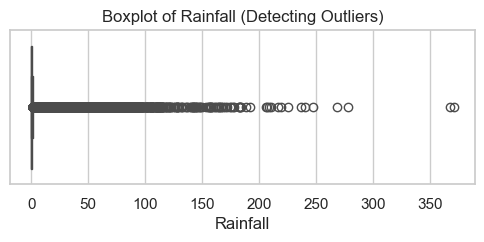

In [12]:
plt.figure(figsize=(6,2))
sns.boxplot(x=df['Rainfall'])
plt.title("Boxplot of Rainfall (Detecting Outliers)")
plt.show()

The output displays records considered extreme based on statistical boundaries.
These may be valid high-value transactions or potential data errors.

### Remove Outliers
We remove values outside the acceptable range.

In [13]:
# Calculate IQR
Q1 = df['Rainfall'].quantile(0.25)
Q3 = df['Rainfall'].quantile(0.75)
IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

outliers_count = df[(df['Rainfall'] < lower) | (df['Rainfall'] > upper)].shape[0]
print(f"Detected {outliers_count} outlier records in Rainfall.")

# Strategy: Capping
# Because we have so many outliers, dropping them would ruin our dataset size. 
# Instead, we "cap" the maximum rainfall to the upper fence.
df['Rainfall'] = np.where(df['Rainfall'] > upper, upper, df['Rainfall'])

print("Outliers capped to the upper bound successfully.")

Detected 28938 outlier records in Rainfall.
Outliers capped to the upper bound successfully.


## Task 4: Normalize Numerical Features
We will normalize a subset of our features using both Min-Max and Z-Score scaling.

In [16]:
!pip install scikit-learn
from sklearn.preprocessing import MinMaxScaler, StandardScaler

features_to_scale = ['MinTemp', 'MaxTemp', 'Rainfall', 'Humidity9am', 'Humidity3pm']

# Min-Max Normalization (Scales between 0 and 1)
min_max_scaler = MinMaxScaler()
df_minmax = pd.DataFrame(min_max_scaler.fit_transform(df[features_to_scale]), columns=features_to_scale)

# Z-Score Normalization (Scales to mean=0, std=1)
z_score_scaler = StandardScaler()
df_zscore = pd.DataFrame(z_score_scaler.fit_transform(df[features_to_scale]), columns=features_to_scale)

print("Z-Score Normalized Data:")
df_zscore.head()

   ---------------------------------------- 0.0/8.0 MB ? eta -:--:--
   ---------------------------------------- 0.0/8.0 MB ? eta -:--:--
   -- ------------------------------------- 0.5/8.0 MB 2.2 MB/s eta 0:00:04
   --------- ------------------------------ 1.8/8.0 MB 4.1 MB/s eta 0:00:02
   ------------- -------------------------- 2.6/8.0 MB 4.4 MB/s eta 0:00:02
   ------------------- -------------------- 3.9/8.0 MB 4.8 MB/s eta 0:00:01
   ---------------------------- ----------- 5.8/8.0 MB 5.3 MB/s eta 0:00:01
   -------------------------------------- - 7.6/8.0 MB 5.8 MB/s eta 0:00:01
   ---------------------------------------- 8.0/8.0 MB 5.7 MB/s eta 0:00:00

   ------------- -------------------------- 1/3 [joblib]
   ------------- -------------------------- 1/3 [joblib]
   ------------- -------------------------- 1/3 [joblib]
   ------------- -------------------------- 1/3 [joblib]
   ------------- -------------------------- 1/3 [joblib]
   -------------------------- ------------- 

,MinTemp,MaxTemp,Rainfall,Humidity9am,Humidity3pm
0,0.189757,-0.044575,0.358714,0.111308,-1.443652
1,-0.752786,0.265794,-0.627098,-1.320650,-1.297105
2,0.111212,0.350440,-0.627098,-1.638863,-1.052860
3,-0.470023,0.674917,-0.627098,-1.267615,-1.736746
4,0.833828,1.281548,1.015921,0.694699,-0.906314


After applying Min-Max normalization, all numerical values are scaled to the range between 0 and 1.

The smallest value in each feature becomes 0, and the largest becomes 1.
All other values are proportionally mapped between these two limits.

Importantly, normalization does NOT change the relative relationships between data points.
If one transaction originally had higher revenue than another, it will still have a higher normalized value.

### Z-Score Normalization
Z-score standardization transforms the data so that:

- The mean of each feature becomes 0
- The standard deviation becomes 1

This is done by subtracting the mean and dividing by the standard deviation:

![zscore.png](img/zscore.png)

This method keeps the shape of the distribution but rescales it around zero.

After standardization, the numerical features are centered around 0.
Values above the original mean become **positive**, and values below the mean become **negative**.

The standard deviation of each feature becomes approximately 1, meaning the spread of the data is standardized.

This transformation is especially useful for:
- Linear regression
- Support Vector Machines (SVM)
- PCA

Because these models assume features are centered and scaled similarly.

## Check Correlation Before Applying PCA

we will check whether numerical features are correlated. If features are strongly correlated, they contain overlapping information.

- **Correlation close to 1**  → Strong positive linear relationship  
  (As one feature increases, the other also increases.)

- **Correlation close to -1** → Strong negative linear relationship  
  (As one feature increases, the other decreases.)

- **Correlation close to 0**  → Weak or no linear relationship  
  (The features do not move together in a predictable linear way.)

In such cases, dimensionality reduction using PCA is meaningful 
because we can combine correlated features into fewer components.

In [ ]:
from sklearn.decomposition import PCA

X = df_zscore.copy()

# Initialize PCA to extract 2 components
pca = PCA(n_components=2)
principal_components = pca.fit_transform(X)

# Interpret Explained Variance
variance = pca.explained_variance_ratio_
print(f"PC1 explains {variance[0]*100:.2f}% of the variance.")
print(f"PC2 explains {variance[1]*100:.2f}% of the variance.")
print(f"Total information retained: {(variance[0]+variance[1])*100:.2f}%")

PC1 explains 50.76% of the variance.
PC2 explains 27.01% of the variance.
Total information retained: 77.77%


## Task 5: Apply PCA and Interpret Explained Variance
We will use the Z-Score standardized data to perform PCA, as PCA is highly sensitive to the scale of variances.

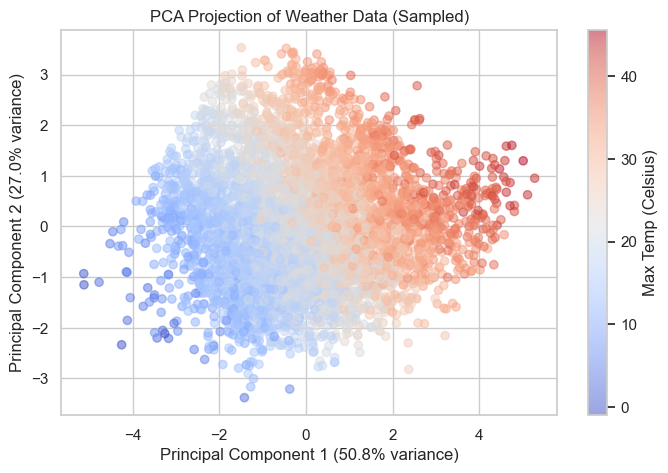

In [18]:
# Visualizing the PCA
# Note: We plot a random sample of 5,000 points to ensure the plot loads smoothly and doesn't crash the browser.

sample_indices = np.random.choice(principal_components.shape[0], 5000, replace=False)

plt.figure(figsize=(8,5))
plt.scatter(principal_components[sample_indices, 0], 
            principal_components[sample_indices, 1], 
            alpha=0.5, 
            c=df['MaxTemp'].iloc[sample_indices], 
            cmap='coolwarm')

plt.colorbar(label='Max Temp (Celsius)')
plt.title("PCA Projection of Weather Data (Sampled)")
plt.xlabel(f"Principal Component 1 ({variance[0]:.1%} variance)")
plt.ylabel(f"Principal Component 2 ({variance[1]:.1%} variance)")
plt.show()

Each point in this plot represents one sales transaction.

The axes no longer represent the original features (Amount and Boxes Shipped).
Instead:

- The horizontal axis represents Principal Component 1 (PC1).
- The vertical axis represents Principal Component 2 (PC2).

PC1 captures the direction of maximum variance in the data.
PC2 captures the second most important direction, perpendicular to PC1.

The spread of points along the horizontal direction indicates how much variation is captured by PC1.
If most of the spread appears horizontally, it suggests that PC1 captures most of the dataset's information.

This projection allows us to visualize high-dimensional data in a lower-dimensional space.

# Assignment

In this assignment, you will:
- **Task 1**
Identify data quality issues in the dataset.

- **Task 2**
Apply one missing value strategy and explain why.

- **Task 3**
Detect and handle outliers using IQR.

- **Task 4**
Normalize numerical features using both Min-Max and Z-score.

- **Task 5**
Apply PCA and interpret explained variance.


End of Assignment 2